# Directional Implicit Spring From Spring Data

This notebook generates target geometries with `SpringFF`, perturbs the spring parameters, then recovers them with `DirectionalImplicitMultipleSystemOptimizer`.


In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import DirectionalImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_systems, _random_spring_ff_param


In [2]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [3]:
systemN = 20
N = 8
N_pairs = 12
max_Za = 3
fixed_atom_indices = [0,1,2]

Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
k, r0 = _random_spring_ff_param(max_Za, k_max=2.0, r0_max=1.5)

ff = SpringFF(max_Za)
ff.reset_parameters(k, r0)
params_star = copy.deepcopy(ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target k', k[1:, 1:].mean().item())
print('sample target r0', r0[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target k 1.192973496987886
sample target r0 0.8072245532969818
sample min distances [0.8728288678188002, 0.5237241996530919, 0.670458517722965]


In [4]:
optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)

perturbed_k = torch.abs(k.clone() + 0.3 * torch.randn_like(k))
perturbed_r0 = torch.abs(r0.clone() + 0.1 * torch.randn_like(r0))
ff.reset_parameters(perturbed_k, perturbed_r0)
params_0 = copy.deepcopy(ff.state_dict())

print('start k mean', params_0['k'][1:, 1:].mean().item())
print('start r0 mean', params_0['r0'][1:, 1:].mean().item())
print('target k mean', params_star['k'][1:, 1:].mean().item())
print('target r0 mean', params_star['r0'][1:, 1:].mean().item())


start k mean 1.0774120190881706
start r0 mean 0.8335350618737256
target k mean 1.192973496987886
target r0 mean 0.8072245532969818


  0%|          | 0/15001 [00:00<?, ?it/s, total_scale=3.767752e-01]

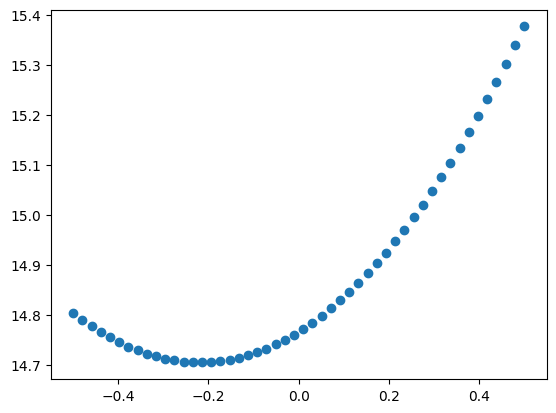

  0%|          | 14/15001 [00:00<03:14, 76.87it/s, total_scale=3.454120e-01]

deviation tensor(-0.2173, dtype=torch.float64, grad_fn=<DivBackward0>)
2.5946614108519284
Fratio 0.006204756766621288
Iteration 0, total_scale: 3.767752e-01


 33%|███▎      | 5000/15001 [00:38<01:13, 136.55it/s, total_scale=3.211569e-03]

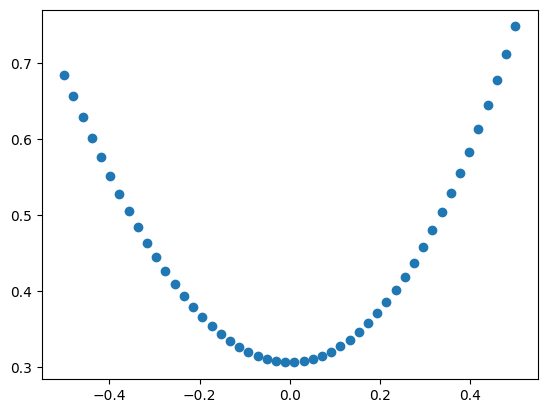

 33%|███▎      | 5014/15001 [00:38<01:23, 120.23it/s, total_scale=1.698213e-03]

deviation tensor(-0.0005, dtype=torch.float64, grad_fn=<DivBackward0>)
3.258901959212475
Fratio -0.023923425811503463
Iteration 5000, total_scale: 3.211569e-03


 67%|██████▋   | 10000/15001 [01:14<00:26, 188.50it/s, total_scale=2.564089e-03]

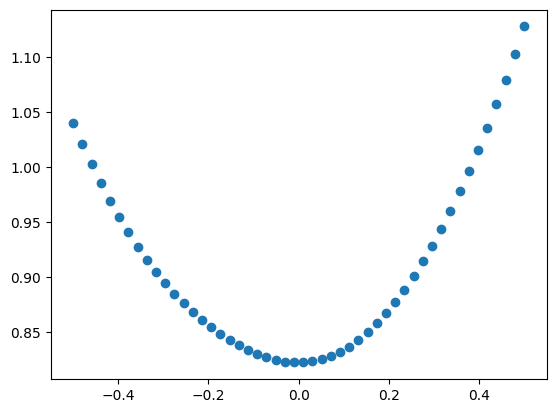

 67%|██████▋   | 10019/15001 [01:14<00:29, 169.73it/s, total_scale=3.936377e-03]

deviation tensor(-0.0009, dtype=torch.float64, grad_fn=<DivBackward0>)
2.1479083346444634
Fratio 0.02889778729271072
Iteration 10000, total_scale: 2.564089e-03


100%|█████████▉| 14994/15001 [01:50<00:00, 114.60it/s, total_scale=1.967296e-03]

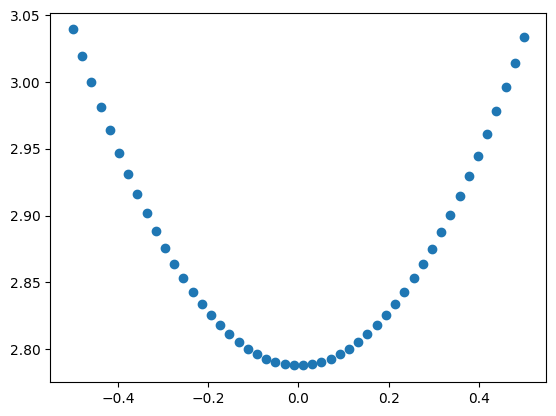

100%|██████████| 15001/15001 [01:50<00:00, 135.96it/s, total_scale=1.967296e-03]

deviation tensor(-0.0006, dtype=torch.float64, grad_fn=<DivBackward0>)
1.9824043644434304
Fratio -0.015265675909850502
Iteration 15000, total_scale: 1.967296e-03
optimization complete


In [5]:
new_params = optimizer.optimize(params_0, lr=1e-3, epoch=15001, print_period=5000, e_size=0.2, eN=9, sg=2)
print('optimization complete')


[1.39060626 0.89110373 0.65737479 0.89106031 1.71117201 0.74487449
 0.65736365 0.74486577 1.58027929]


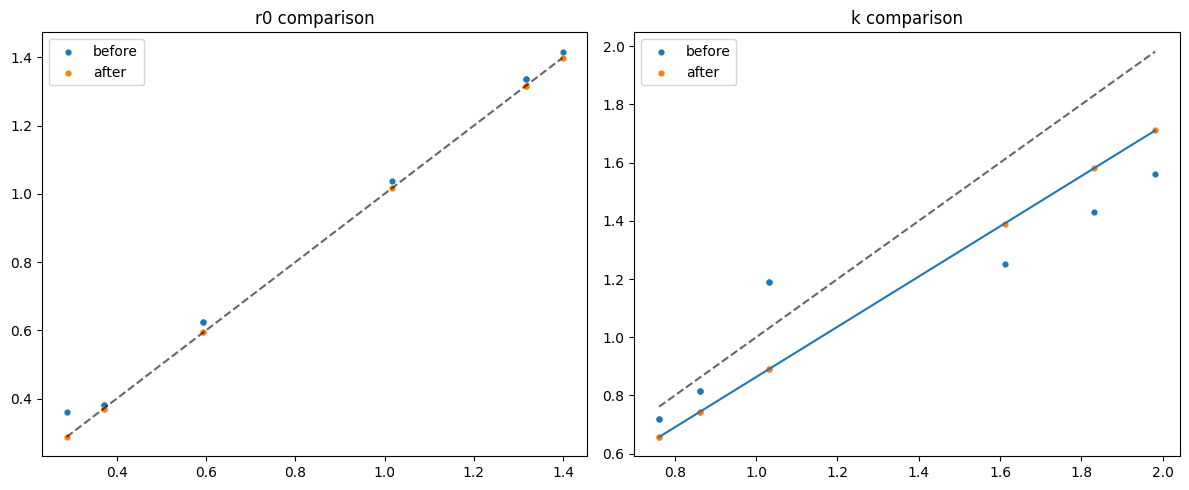

In [6]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
target_r0 = params_star['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_r0 = params_0['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_r0 = new_params['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_r0, before_r0, label='before', s=12)
plt.scatter(target_r0, after_r0, label='after', s=12)
plt.plot([target_r0.min(), target_r0.max()], [target_r0.min(), target_r0.max()], 'k--', alpha=0.6)
plt.title('r0 comparison')
plt.legend()

plt.subplot(1, 2, 2)
target_k = params_star['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_k = params_0['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_k = new_params['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
print(after_k)
plt.scatter(target_k, before_k, label='before', s=12)
plt.scatter(target_k, after_k, label='after', s=12)
plt.plot([target_k.min(), target_k.max()], [target_k.min(), target_k.max()], 'k--', alpha=0.6)
plt.title('k comparison')
plt.legend()
# Linear fits: y = a*x + b
def add_linear_fit(x, y, label, linestyle='-'):
    mask = np.isfinite(x) & np.isfinite(y)
    x_fit_data = x[mask]
    y_fit_data = y[mask]

    a = np.sum(x_fit_data * y_fit_data) / np.sum(x_fit_data**2)
    y_pred = a * x_fit_data

    r2 = 1 - np.sum((y_fit_data - y_pred)**2) / np.sum((y_fit_data - y_fit_data.mean())**2)

    x_line = np.linspace(x_fit_data.min(), x_fit_data.max(), 200)
    y_line = a * x_line

    plt.plot(
        x_line, y_line, linestyle,
        label=f'{label} fit: y={a:.3f}x, R²={r2:.3f}'
    )

add_linear_fit(target_k, after_k, 'after')
plt.tight_layout()
